In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [3]:
df=pd.read_excel("data/Municipal-Personas (1).xlsx") 
#Hemos filtrada para que solo nos salgan los datos de nuestro distrito
df_Uribarri= df[df['Código'].str.startswith('S27', na=False)]
df_Uribarri.head()

,Código,Fecha nacimiento,Zona Servicio,Parentesco,Tipo de persona,Género,Lugar De Nacimiento,Nacionalidad,Municipio,Demandas asociadas,Fechas demandas,Valoraciones asociadas,Fechas valoraciones,Intervenciones asociadas,Fechas intervenciones,Grupales asociadas,Fechas grupales,Expedientes asociados,Fechas expedientes
2973,S27-PER-00194-ASV,02/04/1981,Distrito 2,Madre,Datos persona adulta,Mujer,CAPV,Nacional,Bilbao,S27-DEM-00073-NAS,27/01/2016 - 24/02/2016,S27-VAL-00024-NAS,27/01/2016 - 27/04/2016,"S27-INT-00046-NAS, S27-INT-00045-NAS","30/05/2016 - 23/03/2018, 30/05/2016 - 23/03/2018",S27-PRG-0181-AYM,26/01/2017 - 30/03/2017,S27-EXP-00053-NAS,27/01/2016 - 23/03/2018
2974,S27-PER-00195-IAA,09/12/1985,Distrito 2,Padre,Datos persona adulta,Hombre,CAPV,Nacional,Bilbao,S27-DEM-00073-NAS,27/01/2016 - 24/02/2016,S27-VAL-00024-NAS,27/01/2016 - 27/04/2016,"S27-INT-00046-NAS, S27-INT-00045-NAS","30/05/2016 - 23/03/2018, 30/05/2016 - 23/03/2018",NaN,NaN,S27-EXP-00053-NAS,27/01/2016 - 23/03/2018
2975,S27-PER-00197-NAS,19/05/2014,Distrito 2,Hijo,Datos niño/a joven,Hombre,CAPV,Nacional,Bilbao,S27-DEM-00073-NAS,27/01/2016 - 24/02/2016,S27-VAL-00024-NAS,27/01/2016 - 27/04/2016,"S27-INT-00046-NAS, S27-INT-00045-NAS","30/05/2016 - 23/03/2018, 30/05/2016 - 23/03/2018",NaN,NaN,S27-EXP-00053-NAS,27/01/2016 - 23/03/2018
2976,S27-PER-00546-DDS,05/12/2003,Distrito 2,Hijo,Datos niño/a joven,Hombre,CAPV,Nacional,Bilbao,S27-DEM-00195-DSD,20/09/2016 - 29/09/2016,S27-VAL-00056-DSD,03/05/2016 - 17/08/2016,"S27-INT-00134-DSD, S27-INT-00133-DSD","20/10/2016 - 21/03/2018, 20/10/2016 - 21/03/2018","S27-PRG-0090-DIS, S27-PRG-0075-OPO","30/01/2017 - 31/03/2018, 04/01/2017 - 29/12/2017",S27-EXP-00148-DSD,20/09/2016 - 21/03/2018
2977,S27-PER-00547-ASG,21/01/1966,Distrito 2,Madre,Datos persona adulta,Mujer,CAPV,Nacional,Bilbao,S27-DEM-00195-DSD,20/09/2016 - 29/09/2016,S27-VAL-00056-DSD,03/05/2016 - 17/08/2016,"S27-INT-00134-DSD, S27-INT-00133-DSD","20/10/2016 - 21/03/2018, 20/10/2016 - 21/03/2018",S27-PRG-0075-OPO,04/01/2017 - 29/12/2017,S27-EXP-00148-DSD,20/09/2016 - 21/03/2018


In [4]:
# El análisis exploratorio de los datos

print(df_Uribarri.info())
print(df_Uribarri.describe(include='all'))
print(df_Uribarri.isna().sum())


<class 'pandas.core.frame.DataFrame'>
Index: 1079 entries, 2973 to 4051
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Código                    1079 non-null   object
 1   Fecha nacimiento          1079 non-null   object
 2   Zona Servicio             1079 non-null   object
 3   Parentesco                860 non-null    object
 4   Tipo de persona           1079 non-null   object
 5   Género                    1079 non-null   object
 6   Lugar De Nacimiento       1058 non-null   object
 7   Nacionalidad              1035 non-null   object
 8   Municipio                 1079 non-null   object
 9   Demandas asociadas        1003 non-null   object
 10  Fechas demandas           1003 non-null   object
 11  Valoraciones asociadas    977 non-null    object
 12  Fechas valoraciones       977 non-null    object
 13  Intervenciones asociadas  731 non-null    object
 14  Fechas intervenciones     

In [5]:
#Hemos eliminado las columnas que no aportaban información/estaban repetidas
df_personas=df_Uribarri.drop(["Fecha nacimiento","Zona Servicio","Parentesco","Lugar De Nacimiento","Municipio","Demandas asociadas","Valoraciones asociadas","Fechas valoraciones","Fechas demandas",	"Fechas intervenciones"	,"Grupales asociadas","Fechas grupales","Expedientes asociados","Fechas expedientes"],axis=1)

In [6]:
df_personas.head()

,Código,Tipo de persona,Género,Nacionalidad,Intervenciones asociadas
2973,S27-PER-00194-ASV,Datos persona adulta,Mujer,Nacional,"S27-INT-00046-NAS, S27-INT-00045-NAS"
2974,S27-PER-00195-IAA,Datos persona adulta,Hombre,Nacional,"S27-INT-00046-NAS, S27-INT-00045-NAS"
2975,S27-PER-00197-NAS,Datos niño/a joven,Hombre,Nacional,"S27-INT-00046-NAS, S27-INT-00045-NAS"
2976,S27-PER-00546-DDS,Datos niño/a joven,Hombre,Nacional,"S27-INT-00134-DSD, S27-INT-00133-DSD"
2977,S27-PER-00547-ASG,Datos persona adulta,Mujer,Nacional,"S27-INT-00134-DSD, S27-INT-00133-DSD"


In [7]:
df=pd.read_excel("data/Municipal-Expedientes.xlsx")

#Hemos filtrada para que solo nos salgan los datos de nuestro distrito
df_Uribarri= df[df['Código'].str.startswith('S27', na=False)]

#Hemos eliminado las columnas que no aportaban información/estaban repetidas
df_expedientes=df_Uribarri.drop(["Código","Zona servicio inicial","Fecha cierre","Fecha reapertura","Fecha de cierre (tras reapertura)",	"Zona servicio actual"	,"Estructura familiar inicial"	,"Estructura familiar actual","Demanda Asociada",	"Valoraciones"	,"Programas Grupales",	"Localidad"],axis=1)

In [8]:
df_expedientes.head()

,Fecha inicio,Intervenciones,Cód personas atendidas,Duración
467,06/10/2016,NaN,"S27-PER-08274-BEX, S27-PER-08275-MHB, S27-PER-...","3,13 Mes(es)"
468,27/01/2016,"S27-INT-00045-NAS, S27-INT-00046-NAS","S27-PER-00194-ASV, S27-PER-00195-IAA, S27-PER-...","25,81 Mes(es)"
469,20/09/2016,"S27-INT-00133-DSD, S27-INT-00134-DSD","S27-PER-00546-DDS, S27-PER-00547-ASG, S27-PER-...","18,06 Mes(es)"
470,22/09/2014,"S27-INT-00136-ANN, S27-INT-00137-ANN","S27-PER-00557-NAN, S27-PER-00559-MNE, S27-PER-...","17,58 Mes(es)"
471,18/09/2013,"S27-INT-02411-MMF, S27-INT-02412-MMF","S27-PER-00657-TFC, S27-PER-00658-FMB, S27-PER-...","52,03 Mes(es)"


In [9]:
#Aquí nos apoyamos en tutoriales y la IA para hacer el paso previo al merge.
df_expedientes["Cód personas atendidas"] = df_expedientes["Cód personas atendidas"].str.split(",")
df_exp= df_expedientes.explode("Cód personas atendidas")
df_exp["Cód personas atendidas"] = df_exp["Cód personas atendidas"].str.strip()


In [10]:
#Hicimos el merge de los datasets
df_final = df_exp.merge(
    df_personas,
    left_on="Cód personas atendidas",
    right_on="Código",
    how="left"
)

In [11]:
#Eliminamos columnas repetidas y que ya no eran necesarias como el codigo de personas
df_final=df_final.drop(["Cód personas atendidas","Código","Intervenciones asociadas"],axis=1)

In [12]:
df_final.head()

,Fecha inicio,Intervenciones,Duración,Tipo de persona,Género,Nacionalidad
0,06/10/2016,NaN,"3,13 Mes(es)",Datos persona adulta,Mujer,Extranjera
1,06/10/2016,NaN,"3,13 Mes(es)",Datos persona adulta,Hombre,Doble nacionalidad
2,06/10/2016,NaN,"3,13 Mes(es)",Datos niño/a joven,Mujer,Doble nacionalidad
3,27/01/2016,"S27-INT-00045-NAS, S27-INT-00046-NAS","25,81 Mes(es)",Datos persona adulta,Mujer,Nacional
4,27/01/2016,"S27-INT-00045-NAS, S27-INT-00046-NAS","25,81 Mes(es)",Datos persona adulta,Hombre,Nacional


In [ ]:
#ETL finalizado
# Aseguramos que la columna de fecha sea tipo datetime
df_final["Fecha inicio"] = pd.to_datetime(df_final["Fecha inicio"], dayfirst=True)

# Extraemos el año
df_final["Año"] = df_final["Fecha inicio"].dt.year

# Calculamos intervenciones por año y lo añadimos a cada fila
df_final["intervenciones_por_año"] = df_final.groupby("Año")["Año"].transform("count")
df_final.head()



,Fecha inicio,Intervenciones,Duración,Tipo de persona,Género,Nacionalidad,Año,intervenciones_por_año
0,2016-10-06,NaN,"3,13 Mes(es)",Datos persona adulta,Mujer,Extranjera,2016,109
1,2016-10-06,NaN,"3,13 Mes(es)",Datos persona adulta,Hombre,Doble nacionalidad,2016,109
2,2016-10-06,NaN,"3,13 Mes(es)",Datos niño/a joven,Mujer,Doble nacionalidad,2016,109
3,2016-01-27,"S27-INT-00045-NAS, S27-INT-00046-NAS","25,81 Mes(es)",Datos persona adulta,Mujer,Nacional,2016,109
4,2016-01-27,"S27-INT-00045-NAS, S27-INT-00046-NAS","25,81 Mes(es)",Datos persona adulta,Hombre,Nacional,2016,109


In [15]:
#Cargamos los datos que hemos recopilado

data = pd.read_excel("data/datos.xlsx")

df_uribarri = pd.DataFrame(data)

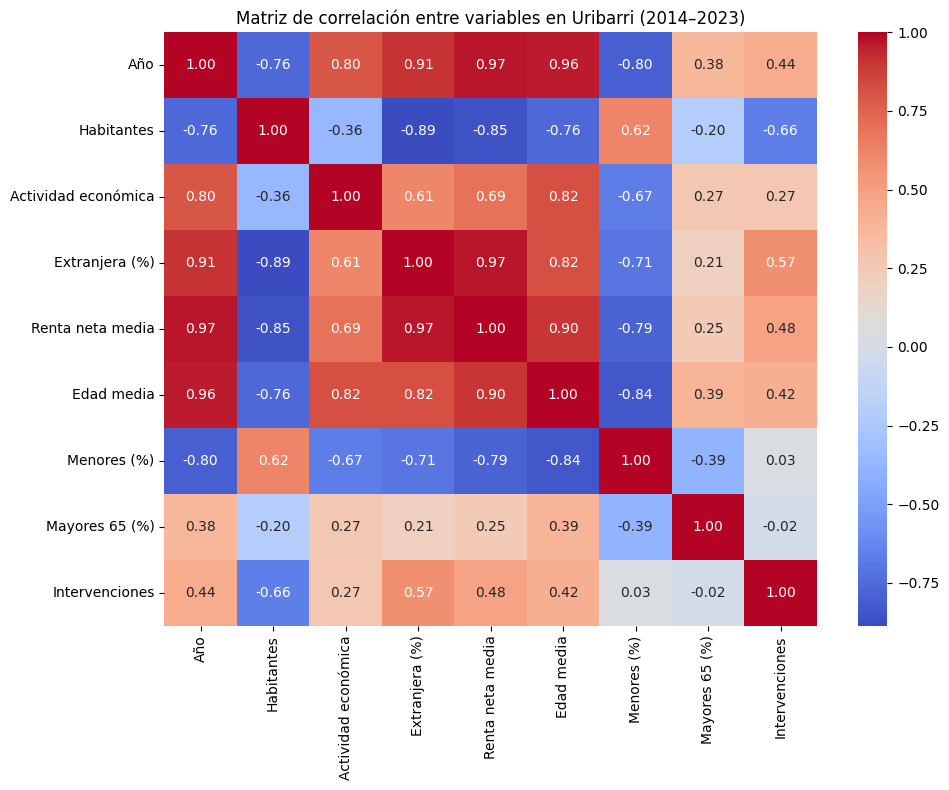

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

#Aquí hicimos una matriz de correlación para ver que variables tenían más relación con la variable objetivo (Intervenciones)
matriz_correlacion = df_uribarri.corr()

plt.figure(figsize=(10,8))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de correlación entre variables en Uribarri (2014–2023)")
plt.tight_layout()
plt.show()
